In [1]:
import pandas as pd
data=pd.read_csv(r"D:\HOPEAI\DS\Data Science-Univate\Week5-Data Science-Univate\Univariate Analysis\Placement.csv")
data.sample()

,sl_no,gender,ssc_p,ssc_b,hsc_p,hsc_b,hsc_s,degree_p,degree_t,workex,etest_p,specialisation,mba_p,status,salary
130,131,M,62.0,Central,65.0,Others,Commerce,60.0,Comm&Mgmt,No,84.0,Mkt&Fin,64.15,Not Placed,NaN


In [2]:
import warnings
warnings.filterwarnings("ignore")

In [3]:
data.shape

(215, 15)

In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 215 entries, 0 to 214
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   sl_no           215 non-null    int64  
 1   gender          215 non-null    object 
 2   ssc_p           215 non-null    float64
 3   ssc_b           215 non-null    object 
 4   hsc_p           215 non-null    float64
 5   hsc_b           215 non-null    object 
 6   hsc_s           215 non-null    object 
 7   degree_p        215 non-null    float64
 8   degree_t        215 non-null    object 
 9   workex          215 non-null    object 
 10  etest_p         215 non-null    float64
 11  specialisation  215 non-null    object 
 12  mba_p           215 non-null    float64
 13  status          215 non-null    object 
 14  salary          148 non-null    float64
dtypes: float64(6), int64(1), object(8)
memory usage: 25.3+ KB


In [5]:
numerical=[]
categorical=[]
for col in data.columns:
    if data[col].dtype=="object":
        categorical.append(col)
    else:
        numerical.append(col)

In [6]:
numerical

['sl_no', 'ssc_p', 'hsc_p', 'degree_p', 'etest_p', 'mba_p', 'salary']

In [7]:
categorical

['gender',
 'ssc_b',
 'hsc_b',
 'hsc_s',
 'degree_t',
 'workex',
 'specialisation',
 'status']

In [8]:
data.describe()

,sl_no,ssc_p,hsc_p,degree_p,etest_p,mba_p,salary
count,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,148.000000
mean,108.000000,67.303395,66.333163,66.370186,72.100558,62.278186,288655.405405
std,62.209324,10.827205,10.897509,7.358743,13.275956,5.833385,93457.452420
min,1.000000,40.890000,37.000000,50.000000,50.000000,51.210000,200000.000000
25%,54.500000,60.600000,60.900000,61.000000,60.000000,57.945000,240000.000000
50%,108.000000,67.000000,65.000000,66.000000,71.000000,62.000000,265000.000000
75%,161.500000,75.700000,73.000000,72.000000,83.500000,66.255000,300000.000000
max,215.000000,89.400000,97.700000,91.000000,98.000000,77.890000,940000.000000


In [9]:
data["ssc_p"].mean()

67.30339534883721

In [9]:
data["ssc_p"].cov(data["hsc_p"])

60.34837332319061

In [10]:
data["ssc_p"].corr(data["hsc_p"])

0.5114721015997726

In [17]:
corr=data[numerical].corr()

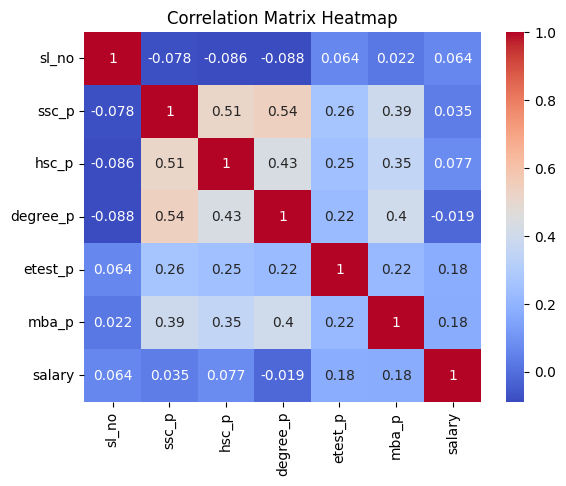

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.heatmap(corr,annot=True,cmap="coolwarm")
plt.title("Correlation Matrix Heatmap")
plt.show()

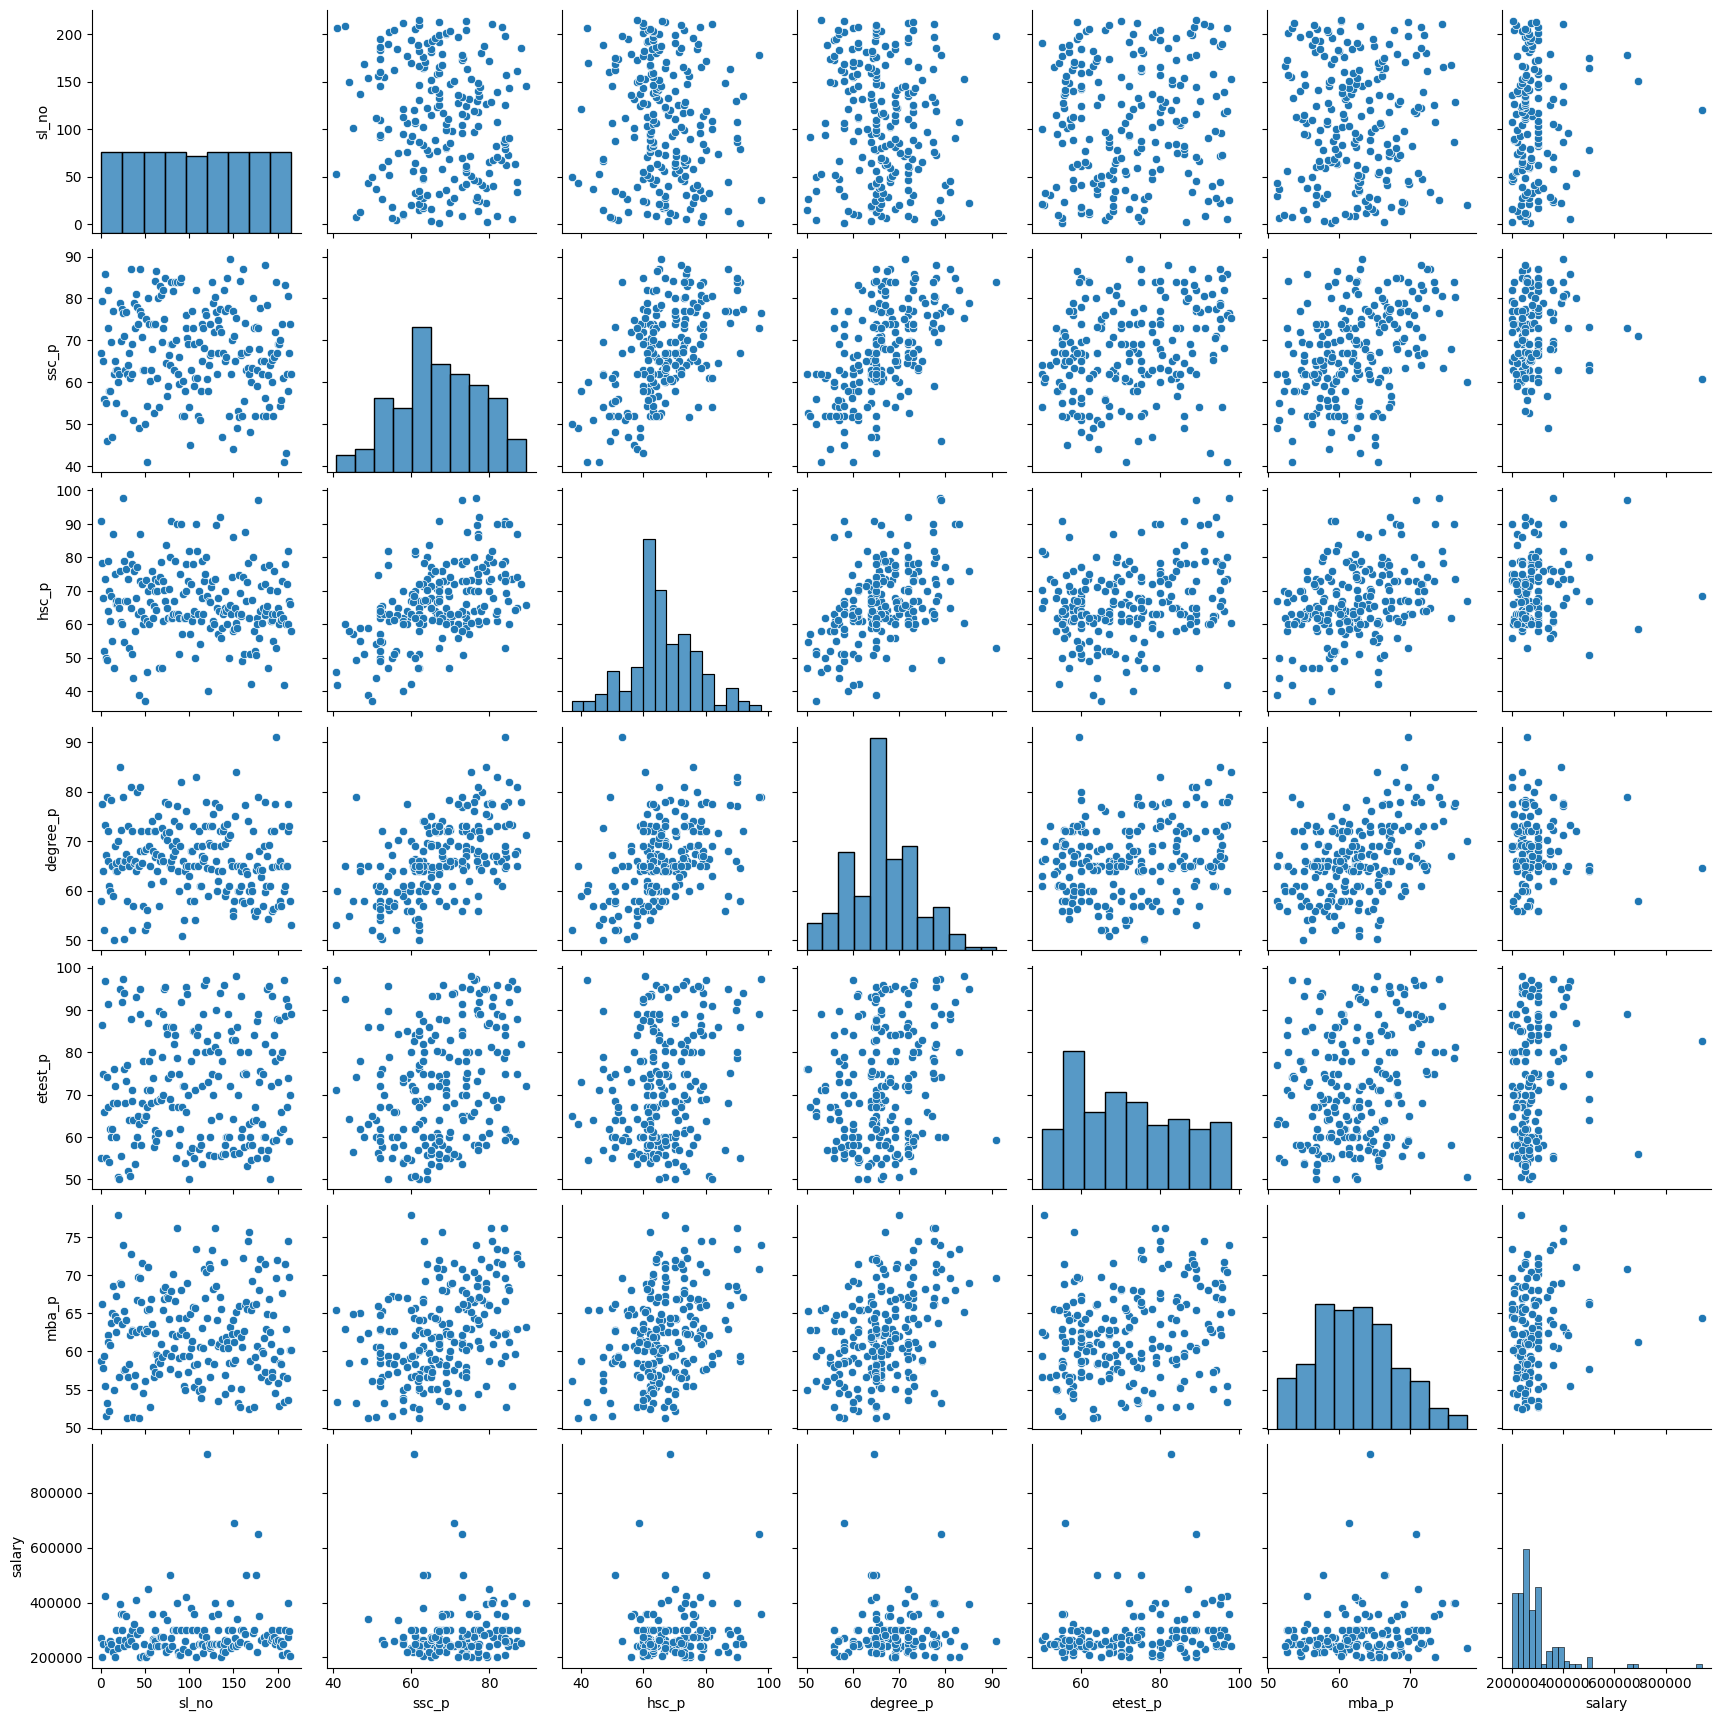

In [22]:
sns.pairplot(data)

### Variance Inflation Factor

In [56]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd
data.fillna(0,inplace=True)
#numerical=data.select_dtypes(include="number")

def vif(X):
    vif_df = pd.DataFrame()
    vif_df["Feature"] = X.columns
    vif_df["VIF"] = [
        variance_inflation_factor(X.values, i)
        for i in range(X.shape[1])
    ]
    return vif_df

vif(numerical.drop(columns=["ssc_p","hsc_p"]))

,Feature,VIF
0,sl_no,4.005392
1,degree_p,95.671066
2,etest_p,32.157153
3,mba_p,97.382146
4,salary,3.079467


### Independent T test

In [60]:
from scipy.stats import ttest_ind

male=data[data["gender"]=="M"]["salary"]
female=data[data["gender"]=="F"]["salary"]

ttest_ind(male,female)

TtestResult(statistic=2.1103433958668765, pvalue=0.03599560646745178, df=213.0)

### p value < 0.05 so Reject Null Hypothesis. There is a significant difference in salaries of both male and female groups

## Paired T Test

In [61]:
from scipy.stats import ttest_rel

ssc=data[data["gender"]=="M"]["ssc_p"]
hsc=data[data["gender"]=="M"]["hsc_p"]

ttest_ind(ssc,hsc)

TtestResult(statistic=0.462536606114424, pvalue=0.6440609938866582, df=276.0)

### p value > 0.05 so Failed to Reject Null Hypothesis. There is no significant difference in 10th and 12th marks of male group

In [64]:
from scipy.stats import f_oneway

f_oneway(data["ssc_p"],data["hsc_p"],data["degree_p"])


F_onewayResult(statistic=0.6719700864663097, pvalue=0.5110602818995302)